# Sparse variational Markov GP — inducing times, non-Gaussian likelihoods and NumPyro

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/sparse_markov_gp.ipynb)

`SparseMarkovGPPrior` is the inducing-time-grid analogue of `MarkovGPPrior`. It wraps any `SDEKernel` and a sorted inducing grid $\mathbf{z}$ of length $M$, exposing the standard SVGP building blocks $(K_{ZZ}, K_{XZ}, \mathrm{diag}\,K_{XX})$ derived from the SDE autocovariance $k(\tau) = H \exp(F\tau) P_\infty H^\top$.

Because the predictive-block contract matches the dense `SparseGPPrior`, the variational guides of `pyrox_gp` (`FullRankGuide`, `MeanFieldGuide`, `WhitenedGuide`) plug straight in. `sparse_markov_elbo` gives the ELBO in closed form for a Gaussian likelihood and by quadrature (a `gaussx` integrator) for any other, and `sparse_markov_factor` registers it in a NumPyro model.

Cost: $\mathcal{O}(M^3 + N M)$ per ELBO evaluation. This is the SVGP construction (Titsias, 2009; Hensman, Fusi & Lawrence, 2013) applied to an SDE kernel; it does not yet exploit the Markov structure of $q(\mathbf{u})$, which the sparse Markovian algorithms of Adam et al. (2020) and Wilkinson, Solin & Adam (2021) do to make the cost linear in $M$.

The notebook covers the Gaussian case with a closed-form $q(\mathbf{u})$, a Poisson likelihood fitted by optimising the ELBO, the same model in NumPyro, and, last, how to choose the inducing grid and when the dense Markov path is the better tool.

## Setup

Detect Colab and install `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when running there. The guides and the Poisson likelihood come from `pyrox_gp`; the Gaussian likelihood from the `pyrox` core.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import equinox as eqx
import gaussx
import jax
import jax.numpy as jnp
import jax.random as jr
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
from numpyro.infer import SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoMultivariateNormal
from pyrox.likelihoods import GaussianLikelihood
from pyrox_gp import FullRankGuide, PoissonLikelihood, WhitenedGuide
from pyrox_ssm import (
    LaplaceMarkovInference,
    MarkovGPPrior,
    MaternSDE,
    SparseConditionedMarkovGP,
    SparseMarkovGPPrior,
    sparse_markov_elbo,
    sparse_markov_factor,
)


jax.config.update("jax_enable_x64", True)
key = jr.PRNGKey(0)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,numpyro,pyrox,matplotlib")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
pyrox     : 0.2.1
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Gaussian likelihood: synthetic regression data

Noisy mixture of two sinusoids on an irregular time grid.

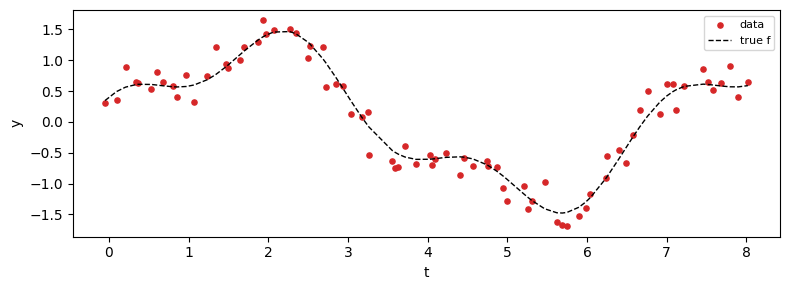

In [4]:
N = 80
t_uniform = jnp.linspace(0.0, 8.0, N)
times = jnp.sort(t_uniform + 0.04 * jr.normal(jr.PRNGKey(1), (N,)))
f_true = 1.2 * jnp.sin(0.9 * times) + 0.4 * jnp.cos(2.7 * times)
y = f_true + 0.18 * jr.normal(key, (N,))

fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(times, y, c="C3", s=14, label="data")
ax.plot(times, f_true, "k--", lw=1, label="true f")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Sparse Markov GP setup

Pick `M = 12` evenly-spaced inducing times and a Matern-3/2 SDE prior. The variational guide is a `FullRankGuide` over the inducing function values $u = f(Z)$.

In [5]:
M = 12
Z = jnp.linspace(times[0], times[-1], M)
sde = MaternSDE(variance=1.0, lengthscale=0.6, order=1)
prior = SparseMarkovGPPrior(sde, Z, jitter=1e-6)
guide = FullRankGuide.init(M, scale=0.3)
lik = GaussianLikelihood(noise_var=0.05)

print(f"M (inducing) = {M}")
print(f"N (data)     = {N}")
print(f"prior marginal variance = {float(prior._stationary_variance()):.3f}")
print(f"initial ELBO = {float(sparse_markov_elbo(prior, guide, lik, times, y)):.3f}")

M (inducing) = 12
N (data)     = 80


prior marginal variance = 1.000


initial ELBO = -767.927


## 3. Conjugate update — closed-form q(u) for a Gaussian likelihood

For Gaussian observations the optimal $q(u) = \mathcal{N}(m_q, S_q)$ is closed-form (Titsias 2009):

$$S_q = (\sigma^{-2} K_{ZZ}^{-1} K_{ZX} K_{XZ} K_{ZZ}^{-1} + K_{ZZ}^{-1})^{-1},\qquad
m_q = \sigma^{-2} S_q K_{ZZ}^{-1} K_{ZX}\,(y - \mu).$$

With $B = K_{ZZ} + \sigma^{-2} K_{ZX} K_{XZ}$ the same solution is $S_q = K_{ZZ} B^{-1} K_{ZZ}$ and $m_q = \sigma^{-2} K_{ZZ} B^{-1} K_{ZX}(y - \mu)$, which the cell below computes with `gaussx` solves on a PSD-tagged operator and no explicit inverse. This sidesteps the need to optimise the ELBO and gives the optimal $q(u)$ at the prescribed inducing locations directly. We use it here to demonstrate the `sparse_markov_elbo` / `SparseConditionedMarkovGP` API on a fitted guide.

In [6]:
def psd(matrix: jax.Array) -> lx.MatrixLinearOperator:
    """Tag a symmetric positive semi-definite matrix for gaussx."""
    return lx.MatrixLinearOperator(matrix, lx.positive_semidefinite_tag)


def optimal_q(
    prior_: SparseMarkovGPPrior, t_: jax.Array, y_: jax.Array, noise_var: float
) -> tuple[jax.Array, jax.Array]:
    """Optimal Gaussian q(u) for a Gaussian likelihood (Titsias, 2009), via gaussx."""
    K_zz_op_, K_xz_, _ = prior_.predictive_blocks(t_)
    K_zz_ = K_zz_op_.as_matrix()
    B = psd(K_zz_ + K_xz_.T @ K_xz_ / noise_var)
    m_q_ = K_zz_ @ gaussx.solve(B, K_xz_.T @ (y_ - prior_.mean(t_))) / noise_var
    S_q_ = K_zz_ @ gaussx.solve_columns(B, K_zz_)
    return m_q_, 0.5 * (S_q_ + S_q_.T)


def cholesky_matrix(cov: jax.Array) -> jax.Array:
    """Lower Cholesky factor of a covariance as a dense array, via gaussx."""
    return gaussx.cholesky(psd(cov)).as_matrix()


sigma2 = 0.05  # observation variance
m_q, S_q = optimal_q(prior, times, y, sigma2)

# Build a guide carrying that closed-form posterior.
L_q = cholesky_matrix(S_q + 1e-9 * jnp.eye(M))
guide = eqx.tree_at(
    lambda g: (g.mean, g.scale_tril),
    guide,
    replace=(m_q, L_q),
)
print(
    f"closed-form ELBO = {float(sparse_markov_elbo(prior, guide, lik, times, y)):.3f}"
)

closed-form ELBO = -116.684


## 4. Posterior at the fitted guide

`SparseConditionedMarkovGP.predict(t_star)` produces the mean / variance at arbitrary test times via the standard SVGP predictive (cost $O(M^3 + |t_*|\,M)$).

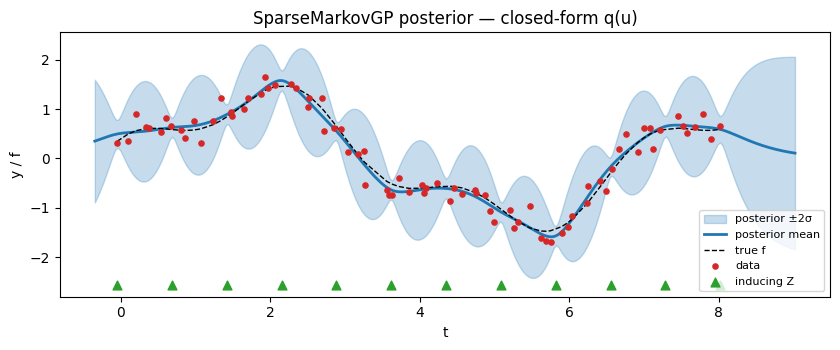

In [7]:
cond = SparseConditionedMarkovGP(prior=prior, guide=guide)
t_star = jnp.linspace(times[0] - 0.3, times[-1] + 1.0, 300)
m_star, v_star = cond.predict(t_star)
m_star, v_star = np.asarray(m_star), np.asarray(v_star)
sd_star = np.sqrt(np.maximum(v_star, 0))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(
    t_star,
    m_star - 2 * sd_star,
    m_star + 2 * sd_star,
    color="C0",
    alpha=0.25,
    label="posterior ±2σ",
)
ax.plot(t_star, m_star, color="C0", lw=2, label="posterior mean")
ax.plot(times, f_true, "k--", lw=1, label="true f")
ax.scatter(times, y, c="C3", s=14, label="data", zorder=3)
ax.scatter(
    Z,
    jnp.full_like(Z, ax.get_ylim()[0] + 0.1),
    c="C2",
    marker="^",
    s=40,
    label="inducing Z",
)
ax.set_xlabel("t")
ax.set_ylabel("y / f")
ax.set_title("SparseMarkovGP posterior — closed-form q(u)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Comparison: sparse vs dense Markov GP

At the closed-form $q(u)$ and well-spaced inducing points, the SVGP posterior should approximate the dense-Markov posterior. The remaining difference is the inducing-set bias from working with $M = 12$ pseudo-points instead of all $N = 80$ data points.

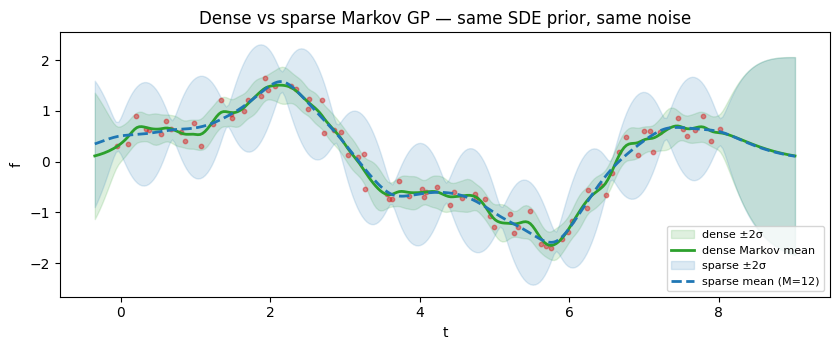

max |sparse mean − dense mean| = 0.2458


In [8]:
dense_prior = MarkovGPPrior(sde, times)
dense_cond = dense_prior.condition(y, jnp.asarray(0.05))
m_dense, v_dense = dense_cond.predict(t_star)
m_dense, v_dense = np.asarray(m_dense), np.asarray(v_dense)
sd_dense = np.sqrt(np.maximum(v_dense, 0))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(
    t_star,
    m_dense - 2 * sd_dense,
    m_dense + 2 * sd_dense,
    color="C2",
    alpha=0.15,
    label="dense ±2σ",
)
ax.plot(t_star, m_dense, color="C2", lw=2, label="dense Markov mean")
ax.fill_between(
    t_star,
    m_star - 2 * sd_star,
    m_star + 2 * sd_star,
    color="C0",
    alpha=0.15,
    label="sparse ±2σ",
)
ax.plot(t_star, m_star, color="C0", lw=2, ls="--", label=f"sparse mean (M={M})")
ax.scatter(times, y, c="C3", s=10, alpha=0.5)
ax.set_xlabel("t")
ax.set_ylabel("f")
ax.set_title("Dense vs sparse Markov GP — same SDE prior, same noise")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print(
    f"max |sparse mean − dense mean| = {float(jnp.max(jnp.abs(m_star - m_dense))):.4f}"
)

## 6. Sweep: how many inducing points do we need?

Increase `M` and re-fit the closed-form $q(u)$. Past a kernel-dependent threshold, the sparse posterior is indistinguishable from the dense one.

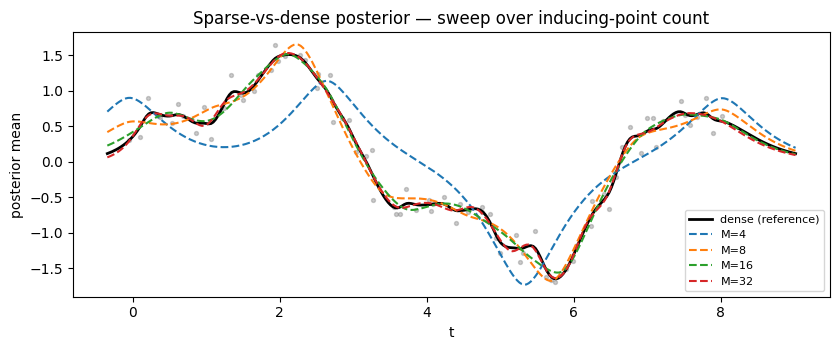

In [9]:
def fit_sparse(M_: int) -> SparseConditionedMarkovGP:
    Z_ = jnp.linspace(times[0], times[-1], M_)
    prior_ = SparseMarkovGPPrior(sde, Z_, jitter=1e-6)
    m_, S_ = optimal_q(prior_, times, y, sigma2)
    L_ = cholesky_matrix(S_ + 1e-9 * jnp.eye(M_))
    g_ = eqx.tree_at(
        lambda g: (g.mean, g.scale_tril),
        FullRankGuide.init(M_, scale=0.3),
        replace=(m_, L_),
    )
    return SparseConditionedMarkovGP(prior=prior_, guide=g_)


fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(t_star, m_dense, color="black", lw=2, label="dense (reference)")
for M_, color in zip([4, 8, 16, 32], ["C0", "C1", "C2", "C3"], strict=True):
    cond_ = fit_sparse(M_)
    m_, _ = cond_.predict(t_star)
    ax.plot(t_star, np.asarray(m_), color=color, lw=1.5, ls="--", label=f"M={M_}")
ax.scatter(times, y, c="grey", s=8, alpha=0.4)
ax.set_xlabel("t")
ax.set_ylabel("posterior mean")
ax.set_title("Sparse-vs-dense posterior — sweep over inducing-point count")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

The table in §9 makes this threshold quantitative.

## 7. A non-Gaussian likelihood: counts

For a non-Gaussian likelihood there is no closed-form $q(\mathbf{u})$, so we maximise the ELBO directly. The data are event counts on an irregular grid, $y_n \sim \mathrm{Poisson}(e^{f(t_n)})$, the kind of series a detection product produces (fire detections, lightning flashes or plume detections per overpass). `sparse_markov_elbo` evaluates the expected log-likelihood $\mathbb{E}_{q(f_n)}[\log p(y_n \mid f_n)]$ by 20-point Gauss–Hermite quadrature.

The guide is a `WhitenedGuide`, which parameterises $q(\mathbf{v}) = \mathcal{N}(\mathbf{m}_v, L_v L_v^\top)$ in whitened coordinates $\mathbf{u} = L_{ZZ}\mathbf{v}$; that keeps the optimisation well conditioned as the kernel hyperparameters move (Hensman, Matthews & Ghahramani, 2015). We optimise the guide and the log-variance and log-lengthscale jointly with Adam.

In [10]:
N_c = 200
t_c = jnp.sort(jr.uniform(jr.PRNGKey(10), (N_c,), minval=0.0, maxval=30.0))
f_c = 0.8 + 1.0 * jnp.sin(0.5 * t_c) + 0.4 * jnp.sin(1.7 * t_c)
y_c = jr.poisson(jr.PRNGKey(11), jnp.exp(f_c)).astype(jnp.float64)
M_c = 30
Z_c = jnp.linspace(0.0, 30.0, M_c)
poisson = PoissonLikelihood()
quadrature = gaussx.GaussHermiteIntegrator(order=20)


class SparseCountFit(eqx.Module):
    """Whitened guide parameters and log-hyperparameters, optimised together."""

    q_mean: jax.Array
    q_tril: jax.Array
    log_variance: jax.Array
    log_lengthscale: jax.Array

    def build(self) -> tuple[SparseMarkovGPPrior, WhitenedGuide]:
        sde = MaternSDE(
            jnp.exp(self.log_variance), jnp.exp(self.log_lengthscale), order=1
        )
        prior = SparseMarkovGPPrior(sde, Z_c, jitter=1e-6)
        diag = jax.nn.softplus(jnp.diag(self.q_tril))
        scale_tril = jnp.tril(self.q_tril, k=-1) + jnp.diag(diag)
        return prior, WhitenedGuide(self.q_mean, scale_tril)


def negative_elbo(fit: SparseCountFit) -> jax.Array:
    prior, guide = fit.build()
    return -sparse_markov_elbo(prior, guide, poisson, t_c, y_c, integrator=quadrature)


fit = SparseCountFit(
    q_mean=jnp.zeros(M_c),
    q_tril=jnp.eye(M_c) * 0.5413,  # softplus(0.5413) = 1, so q starts at the prior
    log_variance=jnp.asarray(0.0),
    log_lengthscale=jnp.asarray(0.0),
)
adam = optax.adam(0.05)
adam_state = adam.init(fit)


@eqx.filter_jit
def adam_step(fit, state):
    value, grads = eqx.filter_value_and_grad(negative_elbo)(fit)
    updates, state = adam.update(grads, state, fit)
    return eqx.apply_updates(fit, updates), state, value


elbo_trace = []
for _ in range(600):
    fit, adam_state, value = adam_step(fit, adam_state)
    elbo_trace.append(-float(value))
print(f"final ELBO: {elbo_trace[-1]:.2f}")
print(f"learned variance:    {float(jnp.exp(fit.log_variance)):.3f}")
print(f"learned lengthscale: {float(jnp.exp(fit.log_lengthscale)):.3f}")

final ELBO: -407.87
learned variance:    1.100
learned lengthscale: 3.595


As a reference, the dense Markov GP fits the same counts with `LaplaceMarkovInference` at the learned hyperparameters, using all 200 observation times instead of 30 inducing times.

RMSE of the posterior mean of f, sparse ELBO (M = 30): 0.279
RMSE of the posterior mean of f, dense Laplace (N = 200): 0.276
max |sparse mean - dense mean|: 0.057


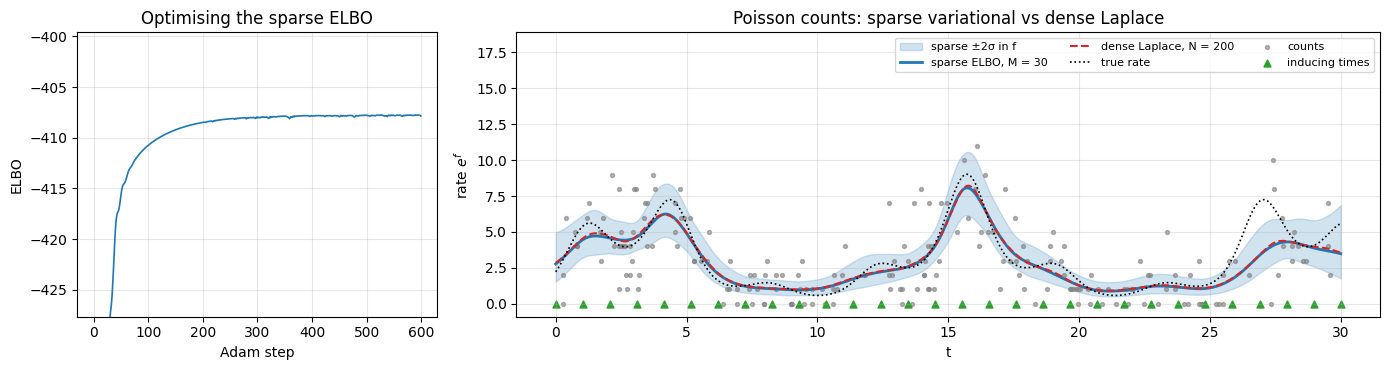

In [11]:
prior_c, guide_c = fit.build()
sparse_count = SparseConditionedMarkovGP(prior=prior_c, guide=guide_c)
t_star_c = jnp.linspace(0.0, 30.0, 400)
m_sp, v_sp = (np.asarray(a) for a in sparse_count.predict(t_star_c))

dense_count = LaplaceMarkovInference(max_iter=30).fit(
    MarkovGPPrior(prior_c.sde_kernel, t_c), poisson, y_c
)
m_dn, v_dn = (np.asarray(a) for a in dense_count.predict(t_star_c))
jax.clear_caches()  # the eager Laplace loop leaves compiled code behind
f_star_c = np.asarray(
    0.8 + 1.0 * jnp.sin(0.5 * t_star_c) + 0.4 * jnp.sin(1.7 * t_star_c)
)
print(
    f"RMSE of the posterior mean of f, sparse ELBO (M = {M_c}): {np.sqrt(np.mean((m_sp - f_star_c) ** 2)):.3f}"
)
print(
    f"RMSE of the posterior mean of f, dense Laplace (N = {N_c}): {np.sqrt(np.mean((m_dn - f_star_c) ** 2)):.3f}"
)
print(f"max |sparse mean - dense mean|: {np.max(np.abs(m_sp - m_dn)):.3f}")

fig, axes = plt.subplots(
    1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2.4]}
)
axes[0].plot(elbo_trace, lw=1.2)
axes[0].set_ylim(
    np.percentile(elbo_trace, 5), max(elbo_trace) + 0.02 * abs(max(elbo_trace))
)
axes[0].set_xlabel("Adam step")
axes[0].set_ylabel("ELBO")
axes[0].set_title("Optimising the sparse ELBO")
axes[0].grid(alpha=0.3)
sd_sp = np.sqrt(np.maximum(v_sp, 0.0))
axes[1].fill_between(
    t_star_c,
    np.exp(m_sp - 2 * sd_sp),
    np.exp(m_sp + 2 * sd_sp),
    color="C0",
    alpha=0.2,
    label="sparse ±2σ in f",
)
axes[1].plot(t_star_c, np.exp(m_sp), color="C0", lw=2, label=f"sparse ELBO, M = {M_c}")
axes[1].plot(
    t_star_c,
    np.exp(m_dn),
    color="C3",
    lw=1.5,
    ls="--",
    label=f"dense Laplace, N = {N_c}",
)
axes[1].plot(t_star_c, np.exp(f_star_c), "k:", lw=1.2, label="true rate")
axes[1].scatter(t_c, y_c, s=8, color="0.5", alpha=0.6, label="counts")
axes[1].scatter(
    Z_c, np.zeros(M_c), marker="^", color="C2", s=25, label="inducing times"
)
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"rate $e^{f}$")
axes[1].set_title("Poisson counts: sparse variational vs dense Laplace")
axes[1].legend(fontsize=8, ncol=3, loc="upper right")
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

With 30 inducing times for 200 counts, the sparse variational posterior and the dense Laplace posterior agree closely, and both recover the true rate about equally well. They are different approximations (a variational $q(\mathbf{u})$ on a coarse grid against a Laplace approximation at every observation), so they are not expected to coincide exactly.

## 8. The same model in NumPyro

`sparse_markov_factor` adds the sparse ELBO to a NumPyro model as a factor. Putting priors on the kernel hyperparameters and registering the whitened guide's parameters as `numpyro.param` sites in the model gives a nested bound: SVI with an automatic guide over $(\sigma^2, \ell)$ maximises

$$\mathbb{E}_{q(\boldsymbol{\theta})}\bigl[\mathcal{L}_{\mathbf{u}}(\boldsymbol{\theta}) + \log p(\boldsymbol{\theta}) - \log q(\boldsymbol{\theta})\bigr] \le \log p(\mathbf{y}),$$

where $\mathcal{L}_{\mathbf{u}}(\boldsymbol{\theta})$ is the sparse ELBO. Variational inference is the appropriate choice here, and MCMC is not: the factor is a lower bound on $\log p(\mathbf{y} \mid \boldsymbol{\theta})$, not the likelihood, so NUTS over $\boldsymbol{\theta}$ with this factor would sample the wrong distribution. For MCMC over the hyperparameters of a Gaussian-likelihood model, use the exact `markov_gp_factor` as in the training notebook. Two hyperparameters make a full-rank guide (`AutoMultivariateNormal`) cheap.

variance     median 0.836   90% interval [0.755, 0.924]
lengthscale  median 3.055   90% interval [2.760, 3.381]
Adam point estimate: variance 1.100, lengthscale 3.595


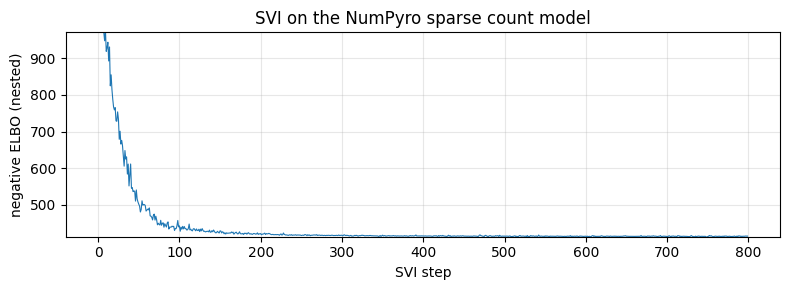

In [12]:
def sparse_count_model(t: jax.Array, y: jax.Array) -> None:
    variance = numpyro.sample("variance", dist.LogNormal(0.0, 1.0))
    lengthscale = numpyro.sample("lengthscale", dist.InverseGamma(3.0, 6.0))
    q_mean = numpyro.param("q_mean", jnp.zeros(M_c))
    q_tril = numpyro.param(
        "q_scale_tril", 0.5 * jnp.eye(M_c), constraint=dist.constraints.lower_cholesky
    )
    prior = SparseMarkovGPPrior(
        MaternSDE(variance, lengthscale, order=1), Z_c, jitter=1e-6
    )
    sparse_markov_factor(
        "elbo",
        prior,
        WhitenedGuide(q_mean, q_tril),
        poisson,
        t,
        y,
        integrator=quadrature,
    )


auto_guide = AutoMultivariateNormal(sparse_count_model)
svi = SVI(sparse_count_model, auto_guide, optax.adam(0.02), Trace_ELBO())
svi_result = svi.run(jr.PRNGKey(12), 800, t_c, y_c, progress_bar=False)
draws = Predictive(auto_guide, params=svi_result.params, num_samples=1000)(
    jr.PRNGKey(13), t_c, y_c
)
for name in ("variance", "lengthscale"):
    q = np.percentile(np.asarray(draws[name]), [5, 50, 95])
    print(f"{name:<12} median {q[1]:.3f}   90% interval [{q[0]:.3f}, {q[2]:.3f}]")
print(
    f"Adam point estimate: variance {float(jnp.exp(fit.log_variance)):.3f}, lengthscale {float(jnp.exp(fit.log_lengthscale)):.3f}"
)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.asarray(svi_result.losses), lw=0.8)
ax.set_ylim(np.percentile(np.asarray(svi_result.losses), [1, 99]))
ax.set_xlabel("SVI step")
ax.set_ylabel("negative ELBO (nested)")
ax.set_title("SVI on the NumPyro sparse count model")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The NumPyro posterior sits at a smaller variance and a shorter lengthscale than the Adam point estimate, which falls outside both 90% intervals. The two are fits to different objectives: the NumPyro model adds priors (the inverse-gamma on $\ell$ has mean 3) and averages over $q(\boldsymbol{\theta})$, and the shift runs along the variance–lengthscale ridge of the training notebook, since $\sigma^2/\ell^3$ is similar for both (about 0.029 against 0.024). Treat the intervals as approximate: one $q(\mathbf{u})$ is shared by every value of $\boldsymbol{\theta}$ the guide proposes, and the variational bound adds its own bias, so they are typically narrower than an exact posterior would be. NumPyro's `AutoMultivariateNormal.sample_posterior` does not handle the model's constrained `numpyro.param` site here, which is why the draws come from `Predictive` over the guide.

## 9. Choosing the inducing grid, and when not to go sparse

### 9.1 How dense must the inducing grid be?

The inducing times must resolve the posterior, so their spacing $\Delta z$ has to be small relative to the lengthscale $\ell$, and how small depends on the kernel's roughness. The cell below draws 1000 noisy observations over 50 lengthscales from Matern GPs of each order and compares the closed-form sparse posterior mean on an evenly spaced grid with the exact dense Markov posterior mean, for spacings from $2\ell$ down to $\ell/8$. The error is the RMSE between the two means, relative to the standard deviation of the dense mean.

spacing dz / ell        2.0      1.0      0.5     0.25    0.125
Matern-1/2            0.553    0.422    0.277    0.167    0.084
Matern-3/2            0.668    0.294    0.098    0.018    0.002
Matern-5/2            0.373    0.140    0.028    0.001    0.000


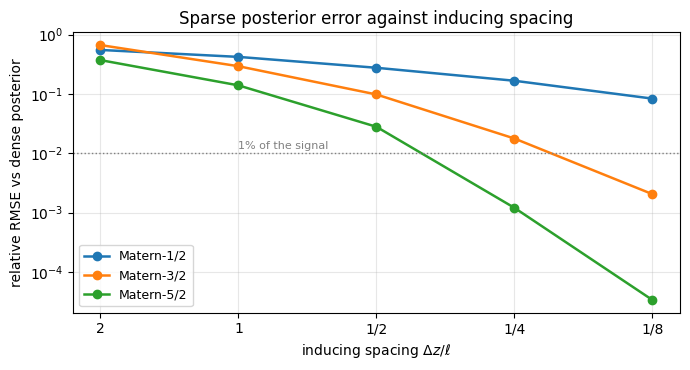

In [13]:
def simulate_gp(sde, t: jax.Array, key: jax.Array) -> jax.Array:
    """Draw f(t) from the SDE prior by forward simulation of its discrete-time model."""
    _F, _L, H, _Q_c, P_inf = sde.sde_params()
    A_seq, Q_seq = sde.discretise_sequence(jnp.diff(t))
    d = sde.state_dim
    k0, k1 = jr.split(key)
    x0 = gaussx.cholesky(psd(P_inf)).mv(jr.normal(k0, (d,)))
    eps = jr.normal(k1, (t.shape[0] - 1, d))

    def step(x, inputs):
        A_k, Q_k, e_k = inputs
        x = A_k @ x + gaussx.cholesky(psd(Q_k + 1e-12 * jnp.eye(d))).mv(e_k)
        return x, x

    _, xs = jax.lax.scan(step, x0, (A_seq, Q_seq, eps))
    return jnp.concatenate([x0[None], xs]) @ H[0]


T_s, N_s, noise_s = 50.0, 1000, 0.05
t_s = jnp.sort(jr.uniform(jr.PRNGKey(20), (N_s,), maxval=T_s))
t_eval = jnp.linspace(0.0, T_s, 1000)


def closed_form_sparse_mean(sde, M_: int, y_s: jax.Array) -> jax.Array:
    """Posterior mean at t_eval from the optimal Gaussian q(u) on an even grid of M_ times."""
    Z_ = jnp.linspace(0.0, T_s, M_)
    prior_ = SparseMarkovGPPrior(sde, Z_, jitter=1e-6)
    K_zz_op_, K_xz_, _ = prior_.predictive_blocks(t_s)
    # Mean at t_eval: K_ez K_zz^{-1} m_q = sigma^{-2} K_ez B^{-1} K_zx y, as in optimal_q.
    B = psd(K_zz_op_.as_matrix() + K_xz_.T @ K_xz_ / noise_s)
    K_ez_ = prior_.predictive_blocks(t_eval)[1]
    return K_ez_ @ gaussx.solve(B, K_xz_.T @ y_s) / noise_s


spacings = [2.0, 1.0, 0.5, 0.25, 0.125]
errors = {}
for order in (0, 1, 2):
    sde_s = MaternSDE(variance=1.0, lengthscale=1.0, order=order)
    y_s = simulate_gp(sde_s, t_s, jr.PRNGKey(30 + order)) + jnp.sqrt(
        noise_s
    ) * jr.normal(jr.PRNGKey(40), (N_s,))
    dense_mean, _ = (
        MarkovGPPrior(sde_s, t_s).condition(y_s, jnp.asarray(noise_s)).predict(t_eval)
    )
    scale = float(jnp.std(dense_mean))
    errors[order] = [
        float(
            jnp.sqrt(
                jnp.mean(
                    (
                        closed_form_sparse_mean(sde_s, int(T_s / dz) + 1, y_s)
                        - dense_mean
                    )
                    ** 2
                )
            )
        )
        / scale
        for dz in spacings
    ]

print(f"{'spacing dz / ell':<18}" + "".join(f"{dz:>9}" for dz in spacings))
for order, errs in errors.items():
    print(
        f"{'Matern-' + str(2 * order + 1) + '/2':<18}"
        + "".join(f"{e:>9.3f}" for e in errs)
    )

fig, ax = plt.subplots(figsize=(7, 3.8))
for order, errs in errors.items():
    ax.loglog(spacings, errs, "o-", lw=1.8, label=f"Matern-{2 * order + 1}/2")
ax.axhline(0.01, color="grey", ls=":", lw=1)
ax.text(spacings[1], 0.012, "1% of the signal", fontsize=8, color="grey")
ax.set_xticks(spacings, ["2", "1", "1/2", "1/4", "1/8"])
ax.minorticks_off()
ax.invert_xaxis()
ax.set_xlabel(r"inducing spacing $\Delta z / \ell$")
ax.set_ylabel("relative RMSE vs dense posterior")
ax.set_title("Sparse posterior error against inducing spacing")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The smooth kernels converge fast: at $\Delta z = \ell/4$ the Matern-5/2 posterior is within 0.1% of the dense one and the Matern-3/2 posterior within 2%. The rough Matern-1/2 kernel converges slowly and is still about 8% off at $\Delta z = \ell/8$: its paths have structure at every scale, so a grid of inducing values cannot summarise them. This is the sparse counterpart of the smoothness choice in the SDE-kernel notebook: a rough kernel needs either a very dense grid or the dense Markov path.

### 9.2 Sparse or dense Markov, for geoscience records?

For a GP over time, the dense Markov path is already linear in $N$. Going sparse pays off only in specific situations, and the $\mathcal{O}(M^3)$ cost of this SVGP construction sets a hard limit:

| Situation | Better path | Why |
|---|---|---|
| Long record with many decorrelation times, e.g. a decade of daily data with a week-long memory | dense Markov | $M$ must grow like $T/\Delta z$; at $\Delta z = \ell/4$ and $T = 500\ell$ that is $M = 2000$ and about $10^{10}$ operations per ELBO, against $\mathcal{O}(N\,d^3)$ for the filter |
| Many observations per decorrelation time, e.g. a 1 Hz sensor whose signal of interest varies over hours | sparse | a few inducing times per $\ell$ summarise thousands of points, and the $\mathcal{O}(NM)$ term stays cheap |
| Rough signals (Matern-1/2) | dense Markov | the inducing grid converges slowly (§9.1) |
| Non-Gaussian likelihood inside a larger NumPyro model fitted by SVI | sparse | `sparse_markov_factor` is a variational objective that composes with other SVI components; the dense strategies are fixed-point loops |
| Hyperparameter posterior by MCMC | dense Markov | `markov_gp_factor` is the exact marginal likelihood; the sparse factor is a bound |

The sparse Markovian algorithms of Adam et al. (2020) and Wilkinson, Solin & Adam (2021) remove the $\mathcal{O}(M^3)$ limit by running Kalman recursions over the inducing times, which would make the first row a case for going sparse as well.

## Summary

- `SparseMarkovGPPrior(sde_kernel, Z)` exposes the SVGP predictive blocks for any state-space kernel, so `pyrox_gp`'s variational guides apply unchanged.
- For a Gaussian likelihood, the optimal $q(\mathbf{u})$ is closed-form; for any other, `sparse_markov_elbo` with a `gaussx` integrator is optimised directly, and on Poisson counts 30 inducing times match a dense Laplace fit on 200 points closely.
- `sparse_markov_factor` puts the sparse ELBO in a NumPyro model; SVI is the right inference there, because the factor is a bound, not a likelihood.
- The inducing spacing must be a fraction of the lengthscale: about $\ell/4$ for smooth kernels (errors of 0.1% to 2% against the dense posterior), and finer than $\ell/8$ for Matern-1/2. With the current $\mathcal{O}(M^3)$ cost, long records with many decorrelation times are better served by the dense Markov path.

**References.**

1. Adam, V., Eleftheriadis, S., Artemev, A., Durrande, N. & Hensman, J. (2020). *Doubly sparse variational Gaussian processes.* AISTATS, PMLR 108, 2874–2884.
2. Hensman, J., Fusi, N. & Lawrence, N. D. (2013). *Gaussian processes for big data.* UAI.
3. Hensman, J., Matthews, A. G. de G. & Ghahramani, Z. (2015). *Scalable variational Gaussian process classification.* AISTATS, PMLR 38, 351–360.
4. Titsias, M. (2009). *Variational learning of inducing variables in sparse Gaussian processes.* AISTATS, PMLR 5, 567–574.
5. Wilkinson, W. J., Solin, A. & Adam, V. (2021). *Sparse algorithms for Markovian Gaussian processes.* AISTATS, PMLR 130, 1747–1755.